# Volumen molar con Peng-Robinson usando Newton-Raphson
**e-Reactor · Termodinámica · Ecuaciones de estado**

En este notebook calculamos el factor de compresibilidad $Z$ y el volumen molar del CO$_2$ con la ecuación de estado de **Peng-Robinson** (1976), resolviendo la cúbica con el método de **Newton-Raphson**.

**Objetivos**
1. Calcular los parámetros $a$, $b$ y $\alpha(T)$ de Peng-Robinson.
2. Escribir la ecuación en forma cúbica en $Z$.
3. Ver cómo el valor inicial de Newton-Raphson decide si llegamos a la raíz de **vapor** o de **líquido**.

## La ecuación de estado

$$P = \frac{RT}{V-b} - \frac{a\,\alpha(T)}{V^2 + 2bV - b^2}$$

con

$$a = 0.45724\,\frac{R^2 T_c^2}{P_c}, \qquad b = 0.07780\,\frac{R T_c}{P_c}$$

$$\kappa = 0.37464 + 1.54226\,\omega - 0.26992\,\omega^2, \qquad \alpha = \left[1 + \kappa\left(1 - \sqrt{T/T_c}\right)\right]^2$$

Definiendo $A = \dfrac{a\alpha P}{R^2T^2}$ y $B = \dfrac{bP}{RT}$, la ecuación queda como una cúbica en $Z = PV/RT$:

$$f(Z) = Z^3 - (1-B)\,Z^2 + (A - 3B^2 - 2B)\,Z - (AB - B^2 - B^3) = 0$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

R = 83.14462618          # cm³·bar/(mol·K)

# Propiedades del CO2 (Poling, Prausnitz y O'Connell, 5.ª ed., apéndice A)
Tc, Pc, w = 304.12, 73.74, 0.225   # K, bar, factor acéntrico

# Condiciones de operación (modifícalas)
T, P = 280.0, 40.0                 # K, bar
print(f"Tr = {T/Tc:.4f}   Pr = {P/Pc:.4f}")

Tr = 0.9207   Pr = 0.5424


In [2]:
a = 0.45724 * R**2 * Tc**2 / Pc
b = 0.07780 * R * Tc / Pc
kappa = 0.37464 + 1.54226*w - 0.26992*w**2
alpha = (1 + kappa*(1 - np.sqrt(T/Tc)))**2

A = a*alpha*P / (R*T)**2
B = b*P / (R*T)

print(f"a = {a:.4e} cm⁶·bar/mol²     b = {b:.3f} cm³/mol")
print(f"kappa = {kappa:.5f}     alpha = {alpha:.5f}")
print(f"A = {A:.5f}     B = {B:.5f}")

a = 3.9646e+06 cm⁶·bar/mol²     b = 26.678 cm³/mol
kappa = 0.70798     alpha = 1.05813
A = 0.30961     B = 0.04584


## Newton-Raphson

$$Z_{k+1} = Z_k - \frac{f(Z_k)}{f'(Z_k)}, \qquad f'(Z) = 3Z^2 - 2(1-B)\,Z + (A - 3B^2 - 2B)$$

- Si empezamos en $Z_0 = 1$ (gas ideal) convergemos a la raíz **mayor** → vapor.
- Si empezamos en $Z_0 = B$ (el volumen más pequeño posible) convergemos a la raíz **menor** → líquido.

In [3]:
def f(Z):
    return Z**3 - (1 - B)*Z**2 + (A - 3*B**2 - 2*B)*Z - (A*B - B**2 - B**3)

def df(Z):
    return 3*Z**2 - 2*(1 - B)*Z + (A - 3*B**2 - 2*B)

def newton(Z0, tol=1e-10, max_iter=50, mostrar=True):
    Z = Z0
    if mostrar:
        print(" k        Z_k            f(Z_k)")
    for k in range(max_iter):
        fz = f(Z)
        if mostrar:
            print(f"{k:2d}   {Z:.10f}   {fz: .3e}")
        Z_nuevo = Z - fz/df(Z)
        if abs(Z_nuevo - Z) < tol:
            return Z_nuevo, k + 1
        Z = Z_nuevo
    raise RuntimeError("Newton-Raphson no convergió")

print("Raíz de VAPOR (Z0 = 1):")
Zv, it_v = newton(1.0)
print("\nRaíz de LÍQUIDO (Z0 = B):")
Zl, it_l = newton(B)

Raíz de VAPOR (Z0 = 1):
 k        Z_k            f(Z_k)
 0   1.0000000000    2.455e-01
 1   0.8116526494    6.589e-02
 2   0.7085442199    1.465e-02
 3   0.6684825793    1.816e-03
 4   0.6619166888    4.504e-05
 5   0.6617453606    3.028e-08
 6   0.6617452452    1.377e-14

Raíz de LÍQUIDO (Z0 = B):
 k        Z_k            f(Z_k)
 0   0.0458377620   -4.202e-03
 1   0.0780481728   -8.139e-04
 2   0.0881002994   -7.174e-05
 3   0.0891743599   -7.946e-07
 4   0.0891865256   -1.016e-10
 5   0.0891865272   -3.469e-18


In [4]:
for nombre, Z, it in (("Vapor", Zv, it_v), ("Líquido", Zl, it_l)):
    V = Z*R*T/P
    print(f"{nombre:8s}  Z = {Z:.5f}   V = {V:8.2f} cm³/mol   ({it} iteraciones)")

V_ideal = R*T/P
print(f"\nGas ideal:  V = {V_ideal:.2f} cm³/mol")

Vapor     Z = 0.66175   V =   385.14 cm³/mol   (7 iteraciones)
Líquido   Z = 0.08919   V =    51.91 cm³/mol   (6 iteraciones)

Gas ideal:  V = 582.01 cm³/mol


### Verificación con `numpy.roots`
Las tres raíces de la cúbica (cuando son reales) corresponden a líquido, una raíz intermedia sin significado físico y vapor.

In [5]:
coef = [1, -(1 - B), A - 3*B**2 - 2*B, -(A*B - B**2 - B**3)]
raices = np.roots(coef)
reales = np.sort(raices[np.abs(raices.imag) < 1e-10].real)
print("Raíces reales de la cúbica:", np.round(reales, 6))

Raíces reales de la cúbica: [0.089187 0.20323  0.661745]


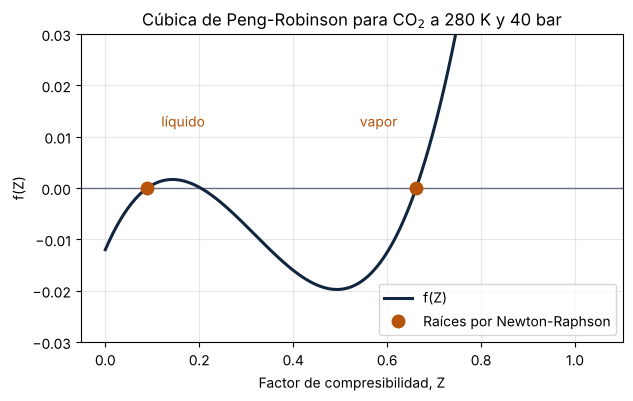

In [6]:
Z = np.linspace(0, 1.05, 400)
fig, ax = plt.subplots(figsize=(7, 4))
ax.axhline(0, color="#667085", lw=1)
ax.plot(Z, f(Z), color="#10263f", lw=2.2, label="f(Z)")
ax.plot([Zl, Zv], [0, 0], "o", color="#b45309", ms=9, label="Raíces por Newton-Raphson")
ax.annotate("líquido", (Zl, 0), (Zl + 0.03, 0.012), color="#b45309")
ax.annotate("vapor", (Zv, 0), (Zv - 0.12, 0.012), color="#b45309")
ax.set_xlabel("Factor de compresibilidad, Z"); ax.set_ylabel("f(Z)")
ax.set_title(f"Cúbica de Peng-Robinson para CO$_2$ a {T:.0f} K y {P:.0f} bar")
ax.set_ylim(-0.03, 0.03); ax.grid(alpha=0.3); ax.legend(loc="lower right")
plt.show()

## ¿Qué aprendimos?
- La misma ecuación tiene **dos raíces físicas** a estas condiciones; el valor inicial decide a cuál llega Newton-Raphson.
- El volumen de vapor es menor que el de gas ideal: a 40 bar el CO$_2$ ya se aleja bastante de la idealidad.
- Para saber cuál fase es la **estable** hay que comparar fugacidades (o la presión de saturación); la cúbica por sí sola no lo dice.

**Para practicar**
1. Cambia a $T = 320$ K (por encima de $T_c$). ¿Cuántas raíces reales quedan?
2. Modifica `newton` para que también imprima el error relativo en cada iteración.
3. Repite el cálculo con Soave-Redlich-Kwong y compara los volúmenes.